# Federal workforce, 2025–2026: the numbers behind the post

This notebook rebuilds everything in the post from OPM's workforce files (EHRI), read from their HuggingFace mirror (impactproject/opm-ehri-data); set VERIFY = True to also check every file against OPM's own copy. It then shows each chart and the tables behind it, section by section in the post's order. Every number is computed by the code; nothing is typed in.

**Set the start year and run all cells.** "Usual" and "normal" mean the average of the years from the start year through 2024. Every rate here is per 1,000 January staff, and OPM's January staff files start in 2012, so the start year can be 2012 or later. The first run downloads one small extract from each of OPM's monthly files, a few thousand reads in all, so it takes hours; later runs read only new or republished files.

Unless a table says otherwise, the numbers are permanent employees, and moving to another agency doesn't count as leaving. Everything is counted by when a hire or departure took effect, not by which month's file it's in. The newest months are still filling in as agencies report late; the late-records table in the 2026 section estimates by how much.

In [1]:
START_YEAR = 2015     # any year from 2012 to 2024
VERIFY = False        # True: also hash every file against OPM's own copy (slow)

In [2]:
import os, subprocess, sys
env = {**os.environ, "FIRST": f"{START_YEAR}01"}
for step in ["extract.py"] + (["verify_opm.py"] if VERIFY else []) + ["build.py", "spot_check.py"]:
    print(f"== {step}", flush=True)
    r = subprocess.run([sys.executable, step], env=env, capture_output=True, text=True)
    if r.returncode:
        print(r.stdout[-2000:], r.stderr[-3000:])
        raise RuntimeError(f"{step} failed")
print("done")

== extract.py


== build.py


== spot_check.py


done


In [3]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_rows", 200, "display.max_columns", 20, "display.width", 200)
T = Path("charts/tables")
CHARTS = pd.read_csv(T / "charts.csv", index_col=0)

def table(name, title, rows=None, path=None, pick=None):
    """Show a table: all of it, its first `rows`, or the rows named in `pick` (an index value, or a list of them)."""
    df = pd.read_csv(path or T / f"{name}.csv", index_col=0, dtype={"code": str, "series": str})
    display(Markdown(f"**{title}**"))
    display(df.loc[pick if isinstance(pick, list) else [pick]] if pick is not None else df if rows is None else df.head(rows))

def chart(prefix):
    name = next(n for n in CHARTS.index if n.startswith(f"{prefix}_"))
    c = CHARTS.loc[name]
    display(Markdown(f"#### {c.headline}\n{c.description}"))
    display(Image(filename=f"charts/{name}.png", width=900))
    display(Markdown(f"*{c.notes}*"))
    if Path(f"charts/{name}.csv").exists():
        table(None, "The numbers in the chart", path=f"charts/{name}.csv")

## A brief review of 2025

#### People who left each year, by years of service
Permanent federal employees who left each year, by years of service.

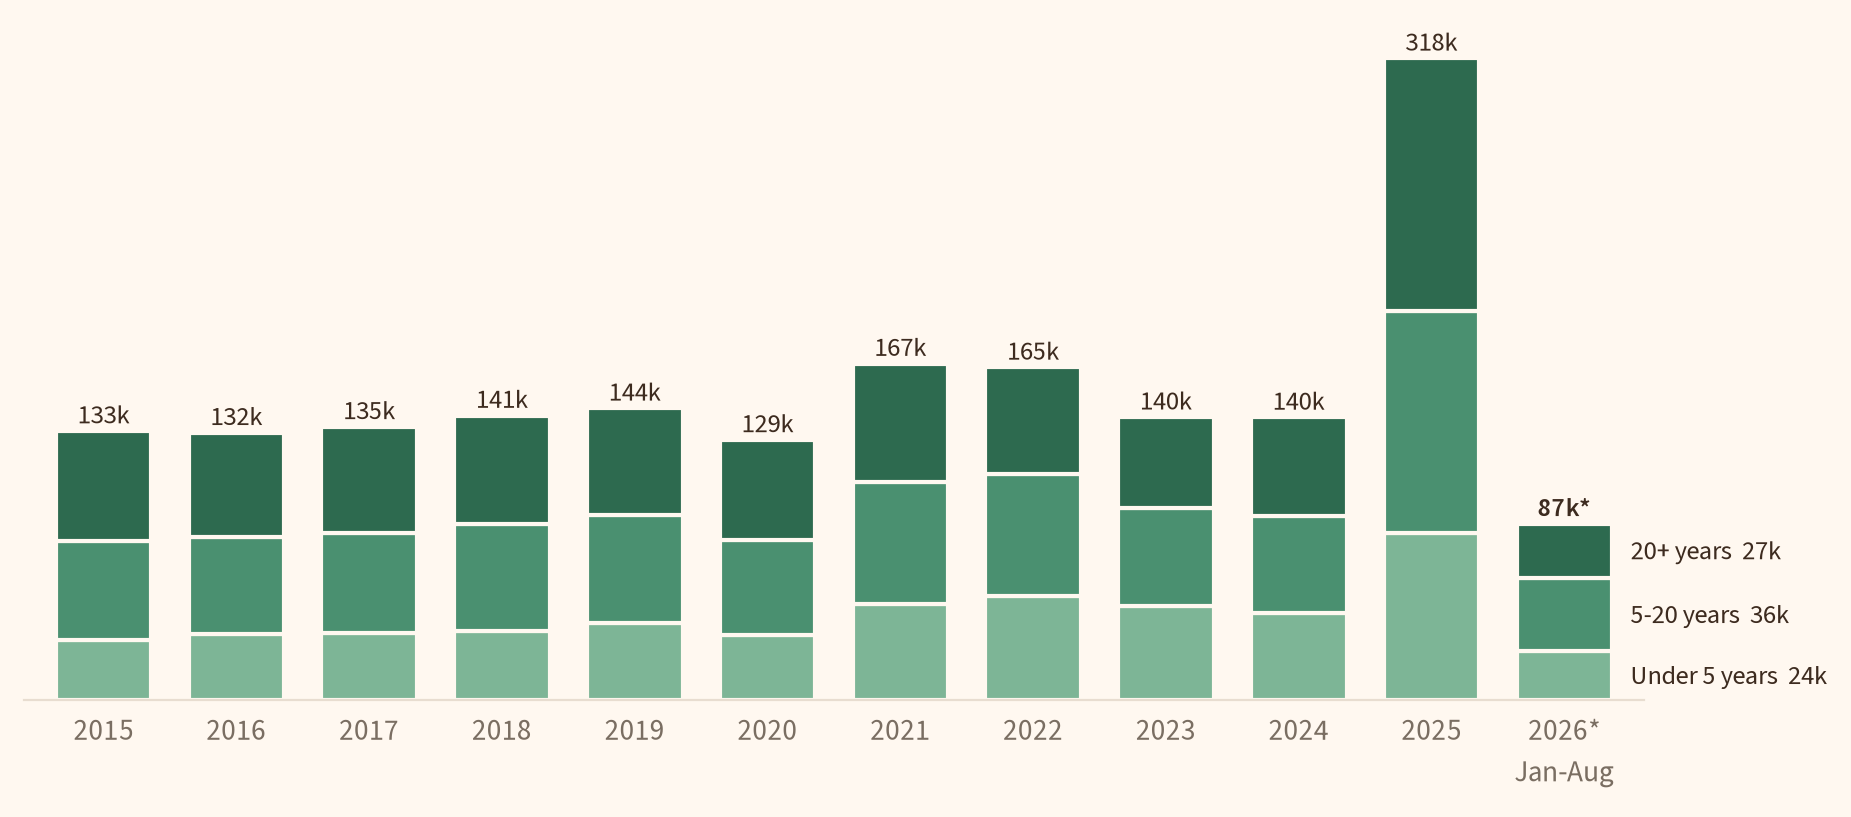

**2026 is January through August only, so its bar is not comparable in height with the full years. DRP exits are included; transfers to other agencies are not. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026. Permanent appointments.*

**The numbers in the chart**

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Under 5 years,29905,32574,33419,34171,38193,32202,47443,51707,46381,43382,82743,24168
5-20 years,48966,47968,49248,52787,53660,47002,60466,60342,48697,47889,109879,36156
20+ years,54284,51769,52562,53865,52550,49570,58604,52591,44916,48619,124905,26957


**Departures each year by type (whole years)**

,Deferred resignation (DRP),Layoff (RIF),Retirement,Quit,Other,total
year,,,,,,
2015,0,351,64958,52983,14865,133157
2016,0,218,61585,55528,14982,132313
2017,0,111,62903,56453,15764,135231
2018,0,221,66443,58467,15692,140823
2019,0,176,65511,62569,16147,144403
2020,0,63,62303,50102,16310,128778
2021,0,189,73738,76997,15594,166518
2022,0,52,65426,84293,14871,164642
2023,0,24,56001,67574,16395,139994


**January 2025 to the newest month: departures by type, new hires, staff**

,January 2025 to August 2026
departures: Deferred resignation (DRP),133357
departures: Layoff (RIF),9834
departures: Retirement,110544
departures: Quit,119213
departures: Other,31860
departures: all,404808
new hires,157455
"permanent staff, January 2025",2164400
"permanent staff, August 2026",1910145


**New hires each year (whole years) and permanent staff each January**

,new hires (whole year),permanent staff in January
year,,
2015,148002,1903850
2016,154896,1926863
2017,122487,1960996
2018,149575,1941087
2019,169559,1955229
2020,161107,1978819
2021,156455,2011274
2022,187507,2008357
2023,228074,2038219


In [4]:
chart(3)
table("2025_departures_by_type", "Departures each year by type (whole years)")
table("2025_since_inauguration", "January 2025 to the newest month: departures by type, new hires, staff")
table("2025_hires_and_staff", "New hires each year (whole years) and permanent staff each January")

### Official layoffs were about 3% of departures, but still drove some occupations' losses

#### How five occupations lost staff in 2025
Permanent staff who left in 2025, as a share of January 2025 staff, by how they left.

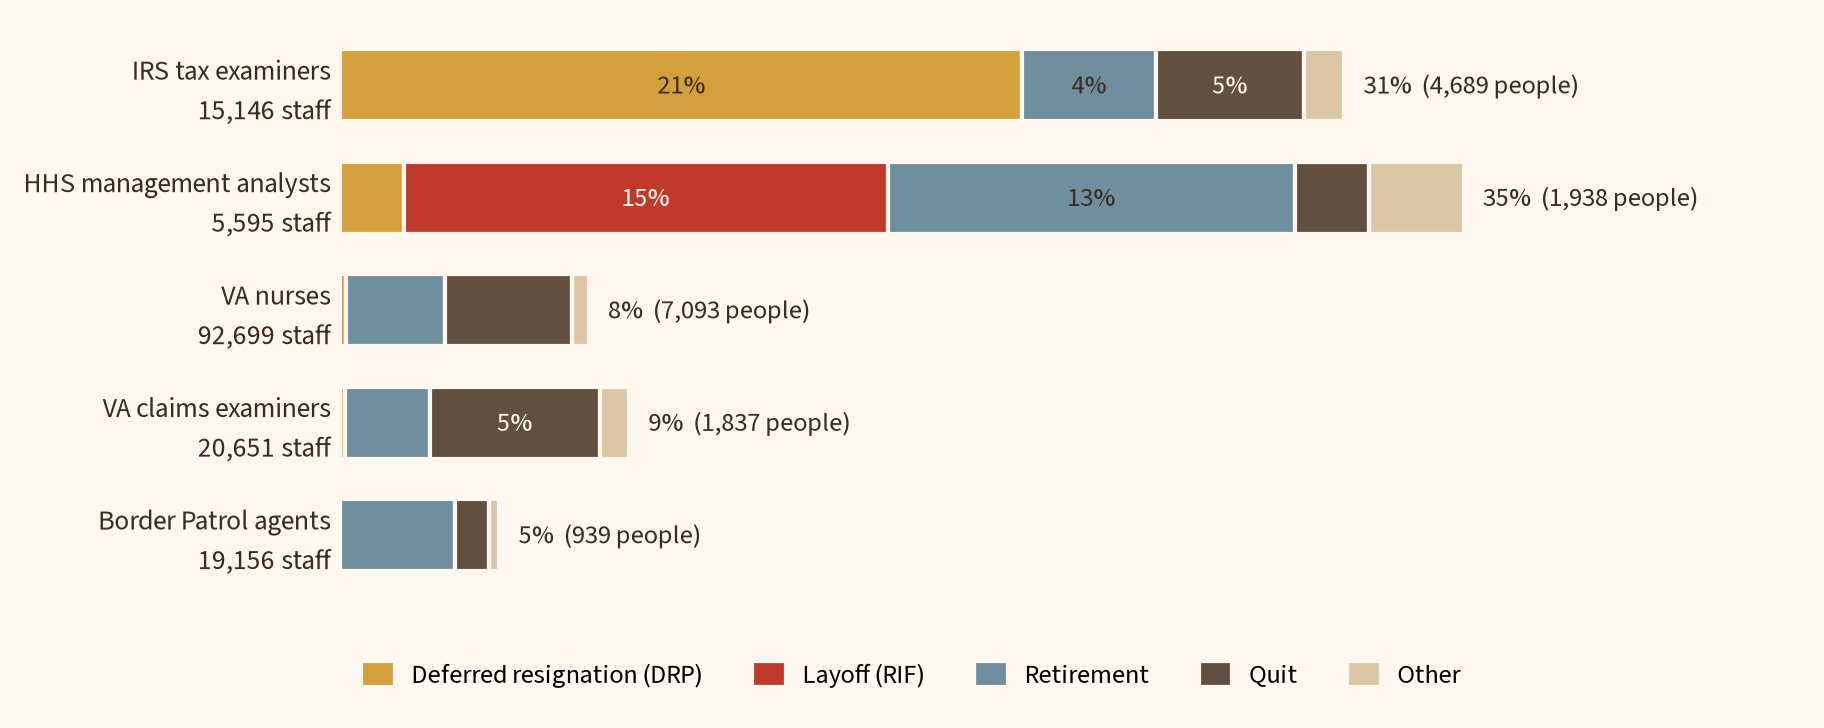

*Layoff (RIF): separations agencies coded as a reduction in force. Other: terminations (expired appointments and other) and OPM's "other separation", which includes removals for discipline or performance, and deaths. Retirement includes disability retirement. Transfers to other agencies are not counted. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026. Permanent appointments.*

**The numbers in the chart**

,Deferred resignation (DRP),Layoff (RIF),Retirement,Quit,Other,january_2025_staff
k,,,,,,
TR 0592,3185,0,623,694,187,15146
HE 0343,109,835,703,127,164,5595
VA 0610,168,0,2820,3620,485,92699
VA 0996,27,0,543,1080,187,20651
HS 1896,0,0,676,201,62,19156


**The five example occupations: how they left in 2025, and new hires that year**

,Deferred resignation (DRP),Layoff (RIF),Retirement,Quit,Other,all departures,January 2025 staff,new hires since,share left,new hires as share of staff
2025 (new hires: 2025 too),,,,,,,,,,
IRS tax examiners,3185,0,623,694,187,4689,15146,278,0.310,0.018
HHS management analysts,109,835,703,127,164,1938,5595,59,0.346,0.011
VA nurses,168,0,2820,3620,485,7093,92699,4217,0.077,0.045
VA claims examiners,27,0,543,1080,187,1837,20651,13,0.089,0.001
Border Patrol agents,0,0,676,201,62,939,19156,2069,0.049,0.108


In [5]:
chart(2)
table("2025_how_people_left", "The five example occupations: how they left in 2025, and new hires that year")

## In 2026, attrition is close to its usual rate, with exceptions

**January-August against normal, as reported and with late records estimated**

,reported so far,estimate with late records,low,high,times normal (estimate),times normal (low),times normal (high),times normal (as reported)
measure,,,,,,,,
departures,87281,92599,89084,98410,1.04,1.00,1.10,0.98
quits,42695,44928,43301,46354,1.10,1.06,1.13,1.04
retirements,33852,36222,34741,39442,0.95,0.92,1.04,0.89
new hires,76217,82349,78928,92515,0.76,0.73,0.85,0.70


**Share of each year's and month's departures that were in that month's own file**

,share of departures in their own month's file
year or month,
2015,0.969
2016,0.921
2017,0.983
2018,0.990
2019,0.979
2020,0.979
2021,0.988
2022,0.912
2023,0.978


**Retirement-eligible permanent staff each January**

,eligible (at least),eligible (at most),staff with age and service,all permanent staff
January of,,,,
2015,160914,441164,1903849,1903850
2016,164143,453992,1926859,1926863
2017,167761,469026,1960989,1960996
2018,170061,479941,1941079,1941087
2019,171915,491054,1955222,1955229
2020,173098,497238,1978812,1978819
2021,179192,507552,2011266,2011274
2022,180612,501398,2008353,2008357
2023,186044,498219,2038212,2038219


**Departures per 1,000 staff per month, by retirement eligibility**

,eligible (at least),possibly eligible,not eligible
"year (per 1,000 staff per month, January-August)",,,
2015,18.69,8.17,3.87
2016,17.72,7.40,3.89
2017,16.48,7.14,3.94
2018,17.54,7.48,4.25
2019,17.28,7.29,4.51
2020,16.19,6.38,3.64
2021,17.36,6.66,4.58
2022,16.23,6.75,5.44
2023,13.36,5.52,4.40


#### Long-serving staff are quitting at about their 2022 peak; retirements are lower
Permanent employees who left per month, per 1,000 on staff in January.

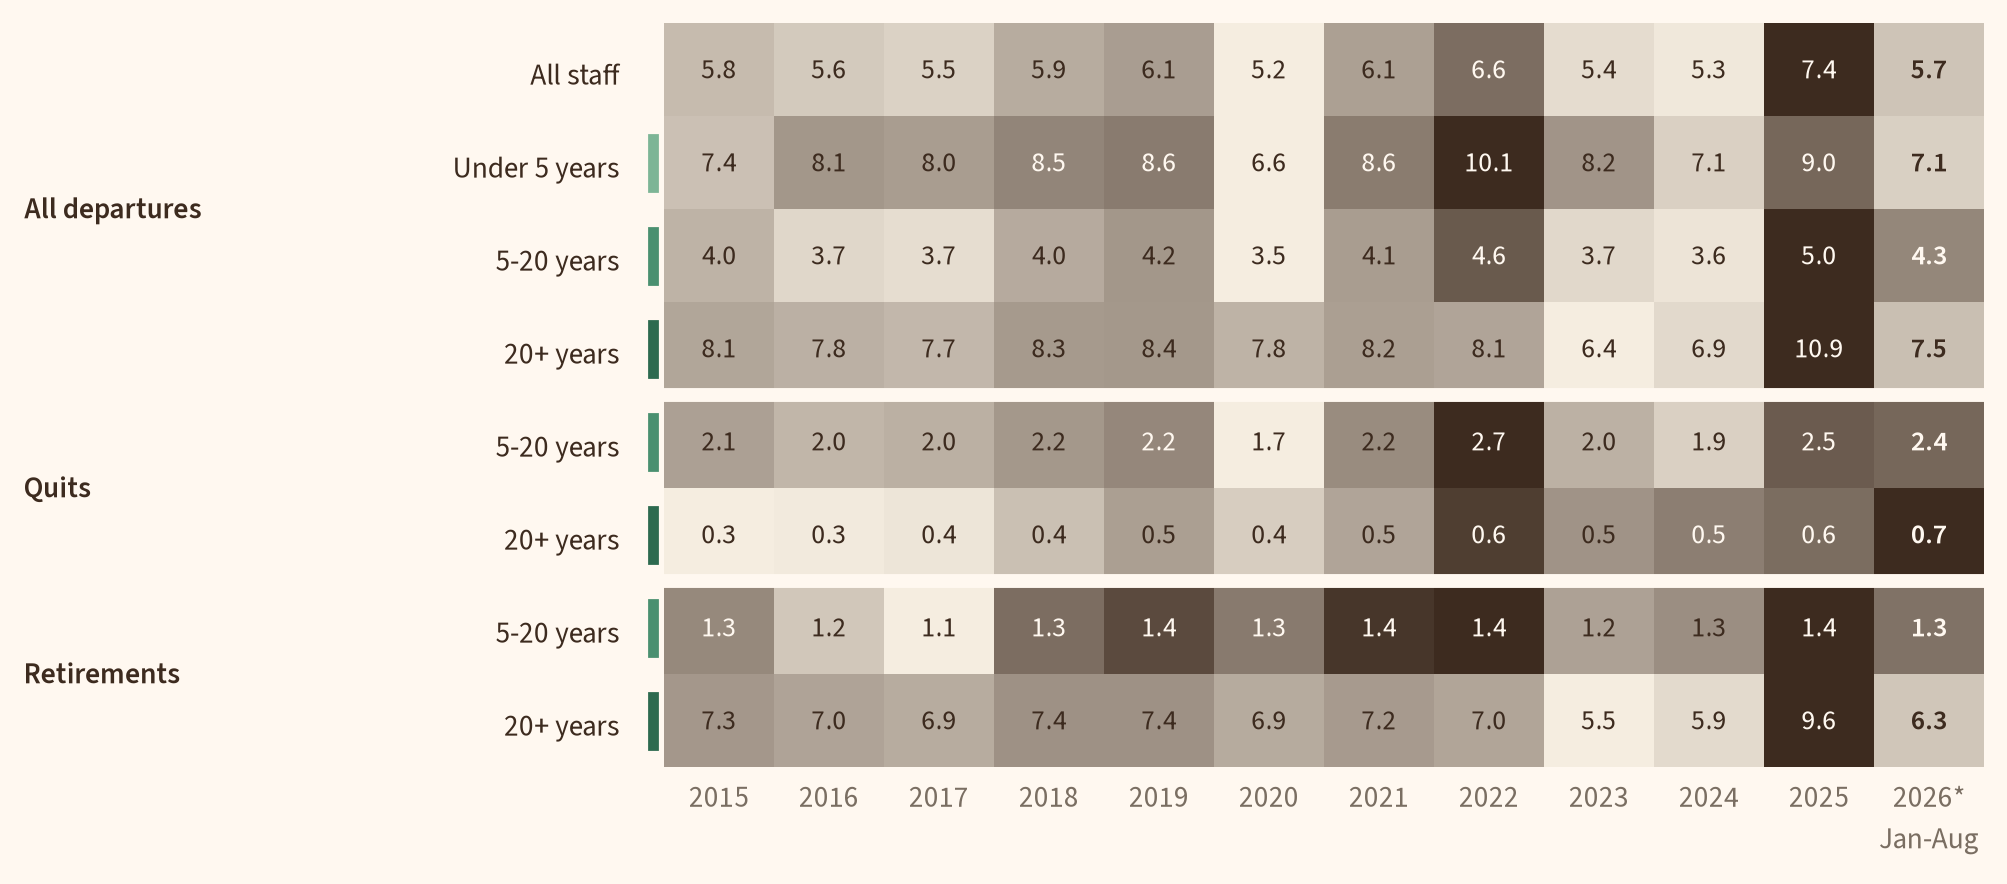

*January through August of every year. Each row is shaded against its own range. DRP exits are included, as quits or retirements depending on how OPM coded them. Transfers to other agencies are not counted. Retirement includes disability retirement. Records for recent months are still arriving: once they do, 2026* figures are likely 1-17% higher. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026. Permanent appointments.*

**The numbers in the chart**

,Unnamed: 1,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
All departures,All permanent staff,5.76,5.60,5.50,5.93,6.09,5.20,6.06,6.62,5.39,5.26,7.37,5.65
All departures,Under 5 years,7.41,8.14,8.03,8.46,8.64,6.60,8.63,10.09,8.20,7.12,9.01,7.12
All departures,5-20 years,3.96,3.69,3.65,4.02,4.17,3.53,4.12,4.61,3.69,3.60,4.96,4.28
All departures,20+ years,8.06,7.82,7.66,8.33,8.36,7.76,8.22,8.10,6.43,6.89,10.88,7.48
Quits,5-20 years,2.10,1.99,2.02,2.15,2.24,1.70,2.22,2.74,2.01,1.85,2.47,2.41
Quits,20+ years,0.34,0.35,0.36,0.42,0.48,0.40,0.47,0.65,0.50,0.53,0.56,0.68
Retirements,5-20 years,1.26,1.15,1.09,1.31,1.37,1.29,1.40,1.42,1.22,1.25,1.42,1.30
Retirements,20+ years,7.28,7.04,6.86,7.42,7.42,6.87,7.23,6.99,5.49,5.88,9.58,6.31


In [6]:
table("2026_vs_normal_with_late_records", "January-August against normal, as reported and with late records estimated")
table("2026_reporting_lag", "Share of each year's and month's departures that were in that month's own file")
table("retirement_eligible_staff", "Retirement-eligible permanent staff each January")
table("2026_departures_by_retirement_eligibility", "Departures per 1,000 staff per month, by retirement eligibility")
chart(4)

### Attorneys are notable for high quit rates

**Occupations with 2,000+ staff and 30+ quits: how many are quitting below their own 2015-2024 high**

,value
occupations compared,148.0
quitting below their 2015-2024 high,127.0
"median, x the old high",0.8


**The same occupations: quit pace against their own 2015-2024 high, highest first**

,name,"quits, January-August 2026","quit pace, x the 2015-2024 high"
series,,,
1801,"General Inspection, Investigation, Enforcement...",1126,2.79
0905,General Attorney,1533,1.83
0028,Environmental Protection Specialist,71,1.63
0861,Aerospace Engineering,275,1.49
0819,Environmental Engineering,49,1.36
2152,Air Traffic Control,232,1.33
0950,Paralegal Specialist,92,1.27
1825,Aviation Safety,51,1.25
1811,Criminal Investigation,283,1.25


**Attorney quits by agency (agencies with 300+ attorneys)**

...

**Departures by years of service and education, against each group's 2015-2024 high**

,January staff,"total, 2026*","quit, 2026*","retire, 2026*","total, x the 2015-2024 high","quit, x the 2015-2024 high","retire, x the 2015-2024 high"
"group (per 1,000 per month, January-August)",,,,,,,
"20+ years, bachelor's",132451,7.21,0.58,6.29,0.90,1.10,0.86
"20+ years, graduate degree",111062,7.69,0.92,6.43,0.97,1.11,0.92
"20+ years, no degree",206610,7.49,0.61,6.21,0.84,0.97,0.80
"5-20 years, bachelor's",298349,3.54,2.07,1.07,0.90,0.84,0.93
"5-20 years, graduate degree",292408,4.54,2.77,1.40,1.11,1.14,0.96
"5-20 years, no degree",462648,4.59,2.40,1.38,0.86,0.77,0.87
"Under 5 years, bachelor's",111486,5.92,5.14,0.04,0.67,0.63,0.74
"Under 5 years, graduate degree",91051,6.01,5.30,0.06,0.88,0.85,0.85
"Under 5 years, no degree",220942,8.18,6.45,0.04,0.67,0.61,0.50


**Mid-career staff with graduate degrees: who the extra quits are**

,January staff,"quits, 2026*","quits, 2015-2024 average","quit rate, 2026*",x the 2015-2024 high,extra quits vs the usual rate
"5-20 years, graduate degree (per 1,000 per month, January-August)",,,,,,
CDC,3412,103,24,3.77,2.66,78
"Attorneys, every agency",19245,922,386,5.99,1.81,520
"VA doctors, nurses and other clinicians",56617,1250,656,2.76,1.18,313
Everyone else,213134,4201,3197,2.46,1.04,1010


#### Attorneys are quitting at nearly twice their old high
Permanent employees who quit per month, per 1,000 on staff in January.

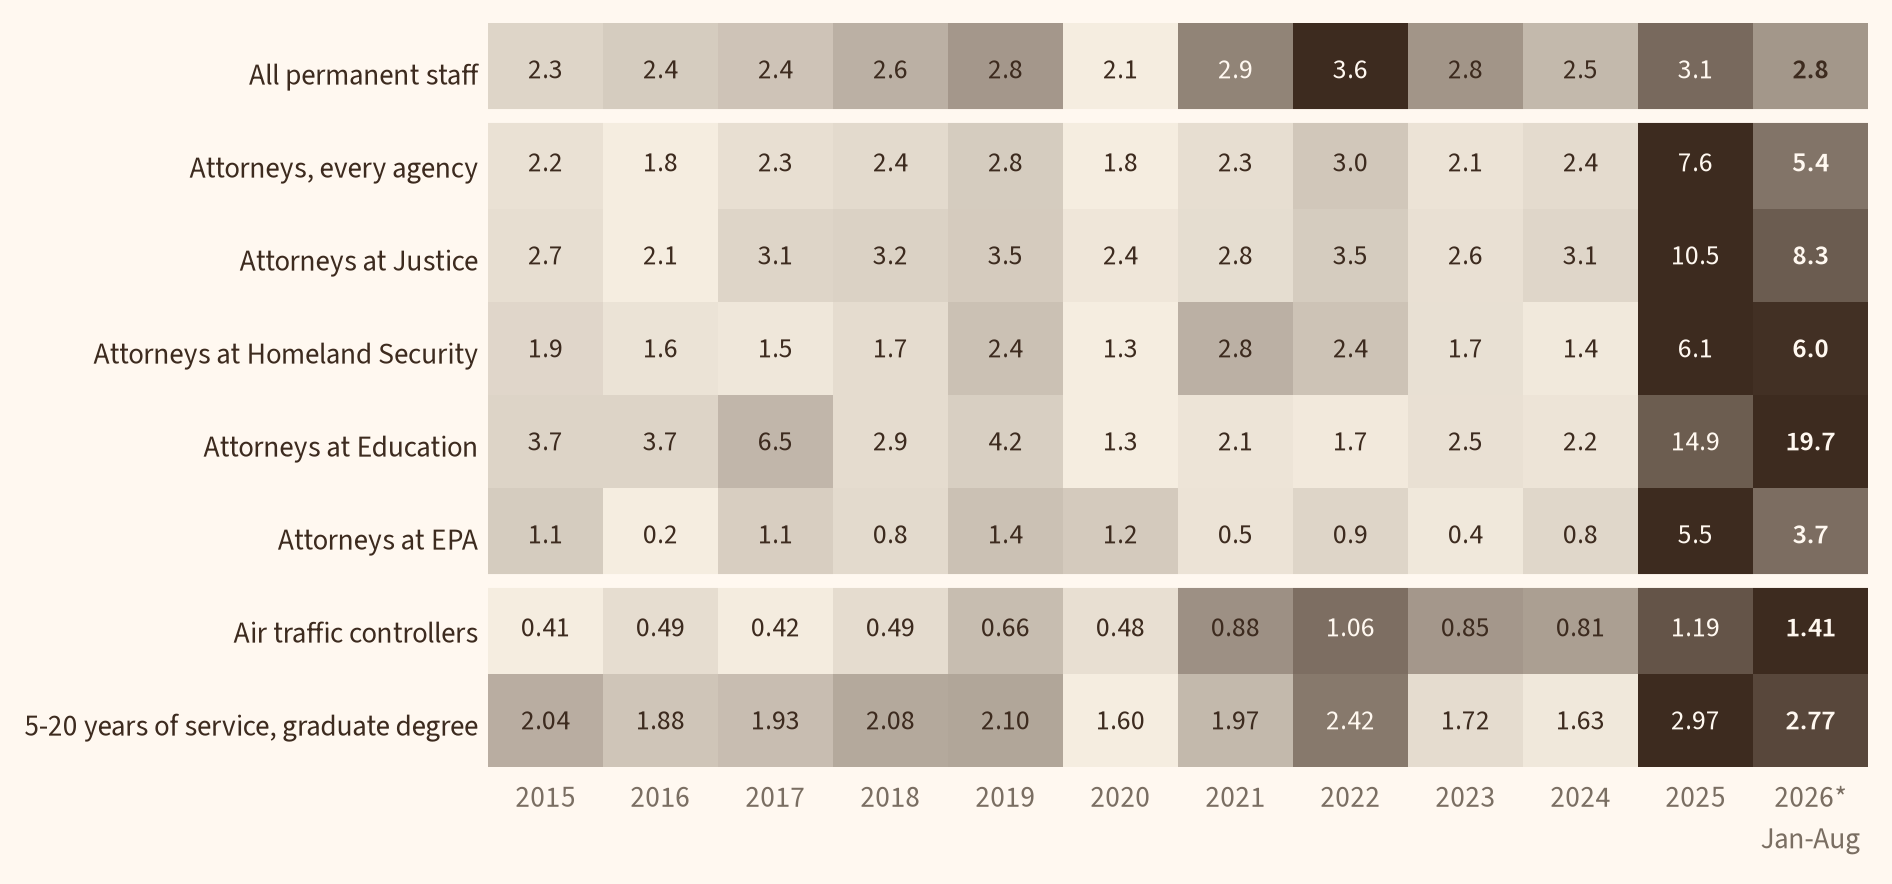

*January through August of every year. Each row is shaded against its own range. Quits include DRP exits that OPM coded as quits. Attorneys: occupational series 0905 (general attorney); the agencies shown are those with 300+ attorneys whose attorneys are quitting at 2+ times their 2015-2024 high. Air traffic controllers: series 2152, every agency. Graduate degree: master's, professional or doctorate. Records for recent months are still arriving: once they do, 2026* quits are likely 1-9% higher. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026. Permanent appointments.*

**The numbers in the chart**

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
All permanent staff,2.30,2.36,2.43,2.57,2.76,2.12,2.90,3.57,2.78,2.51,3.10,2.77
"Attorneys, every agency",2.18,1.83,2.26,2.39,2.82,1.83,2.27,2.96,2.12,2.37,7.64,5.42
Attorneys at Justice,2.73,2.08,3.10,3.24,3.54,2.36,2.79,3.50,2.64,3.08,10.46,8.33
Attorneys at Homeland Security,1.89,1.59,1.48,1.75,2.41,1.33,2.81,2.36,1.66,1.44,6.10,5.97
Attorneys at Education,3.69,3.69,6.50,2.94,4.20,1.34,2.15,1.66,2.53,2.18,14.94,19.69
Attorneys at EPA,1.13,0.25,1.08,0.76,1.43,1.17,0.51,0.90,0.37,0.83,5.49,3.68
Air traffic controllers,0.41,0.49,0.42,0.49,0.66,0.48,0.88,1.06,0.85,0.81,1.19,1.41
"5-20 years of service, graduate degree",2.04,1.88,1.93,2.08,2.10,1.60,1.97,2.42,1.72,1.63,2.97,2.77


In [7]:
table("2026_occupations_below_old_high", "Occupations with 2,000+ staff and 30+ quits: how many are quitting below their own 2015-2024 high")
table("2026_quits_vs_own_high_by_occupation", "The same occupations: quit pace against their own 2015-2024 high, highest first", rows=15)
table("2026_attorney_quits_by_agency", "Attorney quits by agency (agencies with 300+ attorneys)")
table("2026_departures_by_service_and_education", "Departures by years of service and education, against each group's 2015-2024 high")
table("2026_grad_degree_quits_split", "Mid-career staff with graduate degrees: who the extra quits are")
chart(6)

## Hiring is still about a quarter below normal, and back to normal almost nowhere

In [8]:
table("hiring_by_year", "Permanent new hires and transfers between agencies, January-August each year")
table("hiring_by_month", "Permanent new hires by month, newest year")
table("hiring_by_prior_service", "New hires by prior federal service, January-August each year")
table("veterans_share_of_hires", "Veterans among permanent new hires, and among permanent staff")

**Permanent new hires and transfers between agencies, January-August each year**

,permanent new hires,transfers to another agency
year (January-August),,
2015,96324,17948
2016,102608,18532
2017,79196,13654
2018,95276,16376
2019,110701,20721
2020,113765,19344
2021,106992,19243
2022,123587,31036
2023,158692,25004


**Permanent new hires by month, newest year**

,permanent new hires (as reported)
month,
January 2026,7164
February 2026,5841
March 2026,7722
April 2026,8308
May 2026,12212
June 2026,10766
July 2026,10899
August 2026,13305


**New hires by prior federal service, January-August each year**

,no prior federal service,veterans with prior service,non-veterans with prior service,all new hires
year (January-August),,,,
2015,56682,29803,9729,96324
2016,62205,29552,10535,102608
2017,47971,21927,9166,79196
2018,58621,26161,10292,95276
2019,69311,28359,12839,110701
2020,71499,27075,15059,113765
2021,69466,23260,14111,106992
2022,81196,24551,17817,123587
2023,106307,29139,23235,158692


**Veterans among permanent new hires, and among permanent staff**

,veteran new hires,all new hires,share veterans,"veterans' share of permanent staff, January"
year (January-August),,,,
2015,38893,96324,0.404,0.323
2016,38829,102608,0.378,0.326
2017,27825,79196,0.351,0.326
2018,32802,95276,0.344,0.326
2019,35374,110701,0.320,0.324
2020,34590,113765,0.304,0.321
2021,29464,106992,0.275,0.316
2022,30957,123587,0.250,0.310
2023,36616,158692,0.231,0.301


### VA and Homeland Security account for much of the hiring

In [9]:
chart(11)
table("hiring_by_agency", "Agencies averaging 200+ hires: newest year against their average, permanent and every appointment type")
table("named_groups", "The groups the post names: headcount, departures and hires since January 2025, and hiring against normal, permanent and every appointment type")
table("hiring_examples_since_inauguration", "The five example occupations, January 2025 to the newest month: departures and new hires")
table("hiring_dhs_by_occupation", "Homeland Security: occupations against their usual hiring", rows=10)
table("hiring_by_occupation", "Occupations averaging 200+ hires: newest year against their average (the 40 furthest above or below)", rows=40)
table("hiring_by_occupation", "The same table: tax examiners and food inspectors", pick=["0592", "1863"])

**Agencies averaging 200+ hires: newest year against their average**

,name,2026* hires,2015-2024 average,share of average
code,,,,
VA,Department Of Veterans Affairs,21990,28570,0.77
HS,Department Of Homeland Security,10522,10953,0.96
AF,Department Of The Air Force,7039,9017,0.78
NV,Department Of The Navy,6655,12617,0.53
DD,Department Of Defense,6601,6908,0.96
DJ,Department Of Justice,5989,4385,1.37
AR,Department Of The Army,3040,11424,0.27
NN,Nat Aeronautics And Space Administration,2982,618,4.83
AG,Department Of Agriculture,2187,4379,0.50


**The five example occupations, January 2025 to the newest month: departures and new hires**

,departures,new hires,January 2025 staff
January 2025 to August 2026,,,
IRS tax examiners,5218,279,15146
HHS management analysts,2065,122,5595
VA nurses,11171,8748,92699
VA claims examiners,2631,19,20651
Border Patrol agents,1525,5328,19156


**Homeland Security: occupations against their usual hiring**

,name,2026* hires,2015-2024 average,difference
series,,,,
1802,Compliance Inspection And Support,2217,6364,-4147
2210,Information Technology Management,102,248,-146
0343,Management And Program Analysis,74,178,-104
0132,Intelligence,26,114,-88
0930,Hearings And Appeals,53,133,-80
0303,Miscellaneous Clerk And Assistant,6,69,-63
0301,Miscellaneous Administration And Program,166,216,-50
0401,General Natural Resources Management And Biolo...,78,112,-34
0089,Emergency Management Specialist,3,36,-33


**Occupations averaging 200+ hires: newest year against their average (the 40 furthest above or below)**

,name,2026* hires,2015-2024 average,share of average
code,,,,
0610,Nurse,5428,6373,0.85
1896,Border Patrol Enforcement Series,3259,623,5.23
0679,Medical Support Assistance,3096,4171,0.74
2210,Information Technology Management,2416,4057,0.60
1802,Compliance Inspection And Support,2245,6474,0.35
0007,Correctional Officer,1837,1305,1.41
0905,General Attorney,1789,1270,1.41
1801,"General Inspection, Investigation, Enforcement...",1781,1041,1.71
1895,Customs And Border Protection,1756,817,2.15


**The same table: tax examiners and food inspectors**

,name,2026* hires,2015-2024 average,share of average
code,,,,
0592,Tax Examining,1,1220,0.0
1863,Food Inspection,0,253,0.0


### NASA is hiring back after its DRP losses

In [10]:
table("occupations_vs_jan2025", "Every agency occupation with 2,000+ staff (Defense left out): now against January 2025, and arrivals as a share of departures", rows=25)
table("hiring_back_recovered_occupations", "Groups with 2,000+ staff that fell to 90 or below and recovered 5+ points (Defense left out: its monthly counts have gaps)")
table("hiring_up_nn_staff_by_month", "NASA: permanent staff and DRP exits each month")
table("hiring_up_nn_by_occupation", "NASA: occupations with the most extra hires")

**Groups with 2,000+ staff that fell to 90 or below and recovered 5+ points (Defense left out: its monthly counts have gaps)**

,name,low (January 2025 = 100),August 2026 (January 2025 = 100),staff gained since the low,hires and transfers in since the low
agency and series,,,,,
NN 0801,NN 0801 General Engineering,80.3,96.4,538,736
NN 0861,NN 0861 Aerospace Engineering,79.1,86.9,308,420
SZ 0343,SZ 0343 Management And Program Analysis,69.3,90.9,445,0
SZ 2210,SZ 2210 Information Technology Management,72.3,77.7,203,199


**NASA: permanent staff and DRP exits each month**

,permanent staff,DRP exits that month
Nat Aeronautics And Space Administration,,
January 2025,16621.0,0.0
February 2025,16602.0,1.0
March 2025,16528.0,0.0
April 2025,16420.0,3.0
May 2025,16342.0,1.0
June 2025,16323.0,3.0
July 2025,16270.0,10.0
August 2025,16137.0,12.0
September 2025,16037.0,317.0


**NASA: occupations with the most extra hires**

,name,2026* hires,2015-2024 average,extra hires
series,,,,
0801,General Engineering,737,61,676
0861,Aerospace Engineering,421,75,346
2210,Information Technology Management,324,18,306
0899,Engineering And Architecture Student Trainee,432,197,235
0802,Engineering Technical,215,7,208
0301,Miscellaneous Administration And Program,162,14,148
0850,Electrical Engineering,102,9,93
0854,Computer Engineering,78,12,66
0830,Mechanical Engineering,64,3,61


### Temporary and term hiring is down even more

In [11]:
table("hiring_all_appointments", "New hires by appointment type, January-August each year")
table("hiring_temp_by_agency", "Temporary and term hires: agencies with the biggest shortfalls")

**New hires by appointment type, January-August each year**

,all new hires,permanent,temporary and term
year (January-August),,,
2015,167102,96324,70778
2016,171217,102608,68609
2017,141719,79196,62523
2018,163154,95276,67878
2019,181903,110701,71202
2020,187834,113765,74069
2021,175352,106992,68360
2022,180797,123587,57210
2023,220895,158692,62203


**Temporary and term hires: agencies with the biggest shortfalls**

,name,2026* hires,2015-2024 average,difference
code,,,,
AG,Department Of Agriculture,5383,11550,-6167
AR,Department Of The Army,2301,7453,-5152
VA,Department Of Veterans Affairs,5004,8264,-3260
AF,Department Of The Air Force,2937,5635,-2698
IN,Department Of Interior,8389,10373,-1984
CM,Department Of Commerce,1974,3831,-1857
HE,Department Of Health And Human Services,647,2238,-1591
SB,Small Business Administration,147,1141,-994
HS,Department Of Homeland Security,2230,3143,-913


### New hires' education levels are about the same

In [12]:
table("education_of_new_hires", "Education of permanent new hires (agencies with unreliable education records left out)")
table("education_by_occupation_2026", "The change in the share with a bachelor's or more, split into which jobs are being filled (mix) and education within the same jobs")

**Education of permanent new hires (agencies with unreliable education records left out)**

,bachelor's,graduate degree,high school or less,some college,bachelor's or more
year (January-August),,,,,
2015,0.268,0.215,0.257,0.261,0.482
2016,0.269,0.210,0.262,0.259,0.478
2017,0.267,0.210,0.268,0.255,0.477
2018,0.267,0.183,0.317,0.234,0.450
2019,0.244,0.187,0.385,0.184,0.431
2020,0.268,0.217,0.335,0.180,0.485
2021,0.263,0.219,0.321,0.196,0.483
2022,0.254,0.216,0.333,0.198,0.470
2023,0.259,0.217,0.335,0.189,0.476


**The change in the share with a bachelor's or more, split into which jobs are being filled (mix) and education within the same jobs**

,name,share of 2015-2024 hires,share of these hires,"bachelor's or more, 2015-2024","bachelor's or more, now",mix part (points),within part (points)
series,,,,,,,
all,ALL OCCUPATIONS,1.000,1.000,0.471,0.457,-1.087,-0.289
1896,Border Patrol Enforcement Series,0.007,0.052,0.258,0.208,-0.966,-0.261
0610,Nurse,0.068,0.084,0.784,0.855,0.499,0.595
1802,Compliance Inspection And Support,0.070,0.036,0.244,0.278,0.768,0.123
1801,"General Inspection, Investigation, Enforcement...",0.009,0.024,0.603,0.426,0.194,-0.417
0962,Contact Representative,0.014,0.014,0.365,0.135,-0.003,-0.322
1895,Customs And Border Protection,0.009,0.028,0.380,0.423,-0.173,0.120
0185,Social Work,0.014,0.018,0.983,0.988,0.235,0.008
0105,Social Insurance Administration,0.006,0.006,0.732,0.354,-0.005,-0.220


## Young people are a larger share of a smaller hiring pool

**Permanent new hires under 30**

,young hires (under 30),hires with age reported,share young,"share young, Homeland Security left out"
year (January-August),,,,
2015,26634,96324,0.277,0.260
2016,29036,102608,0.283,0.264
2017,22678,79160,0.286,0.269
2018,28588,95150,0.300,0.274
2019,31608,110089,0.287,0.263
2020,30759,112637,0.273,0.265
2021,30924,106992,0.289,0.274
2022,34242,123587,0.277,0.259
2023,43534,158692,0.274,0.264


**The change in the young share, split into which jobs are being filled (mix) and age within the same jobs**

,name,share of 2015-2024 hires,share of these hires,"young, 2015-2024","young, now",mix part (points),within part (points)
series,,,,,,,
all,ALL OCCUPATIONS,1.000,1.000,0.284,0.317,1.365,1.917
1896,Border Patrol Enforcement Series,0.006,0.043,0.667,0.629,1.425,-0.163
1802,Compliance Inspection And Support,0.058,0.029,0.509,0.389,-0.638,-0.354
0456,Wildland Fire Management,0.000,0.018,0.526,0.658,0.430,0.237
0007,Correctional Officer,0.012,0.024,0.546,0.505,0.326,-0.101
1895,Customs And Border Protection,0.007,0.023,0.484,0.501,0.314,0.039
0462,Forestry Technician,0.011,0.002,0.606,0.465,-0.287,-0.029
0610,Nurse,0.057,0.071,0.114,0.103,-0.241,-0.075
0861,Aerospace Engineering,0.003,0.008,0.612,0.471,0.144,-0.106


#### Pathways hiring is down about two-thirds
New hires through Pathways (internships, Recent Graduates, Presidential Management Fellows), January-August of each year, all appointment types.

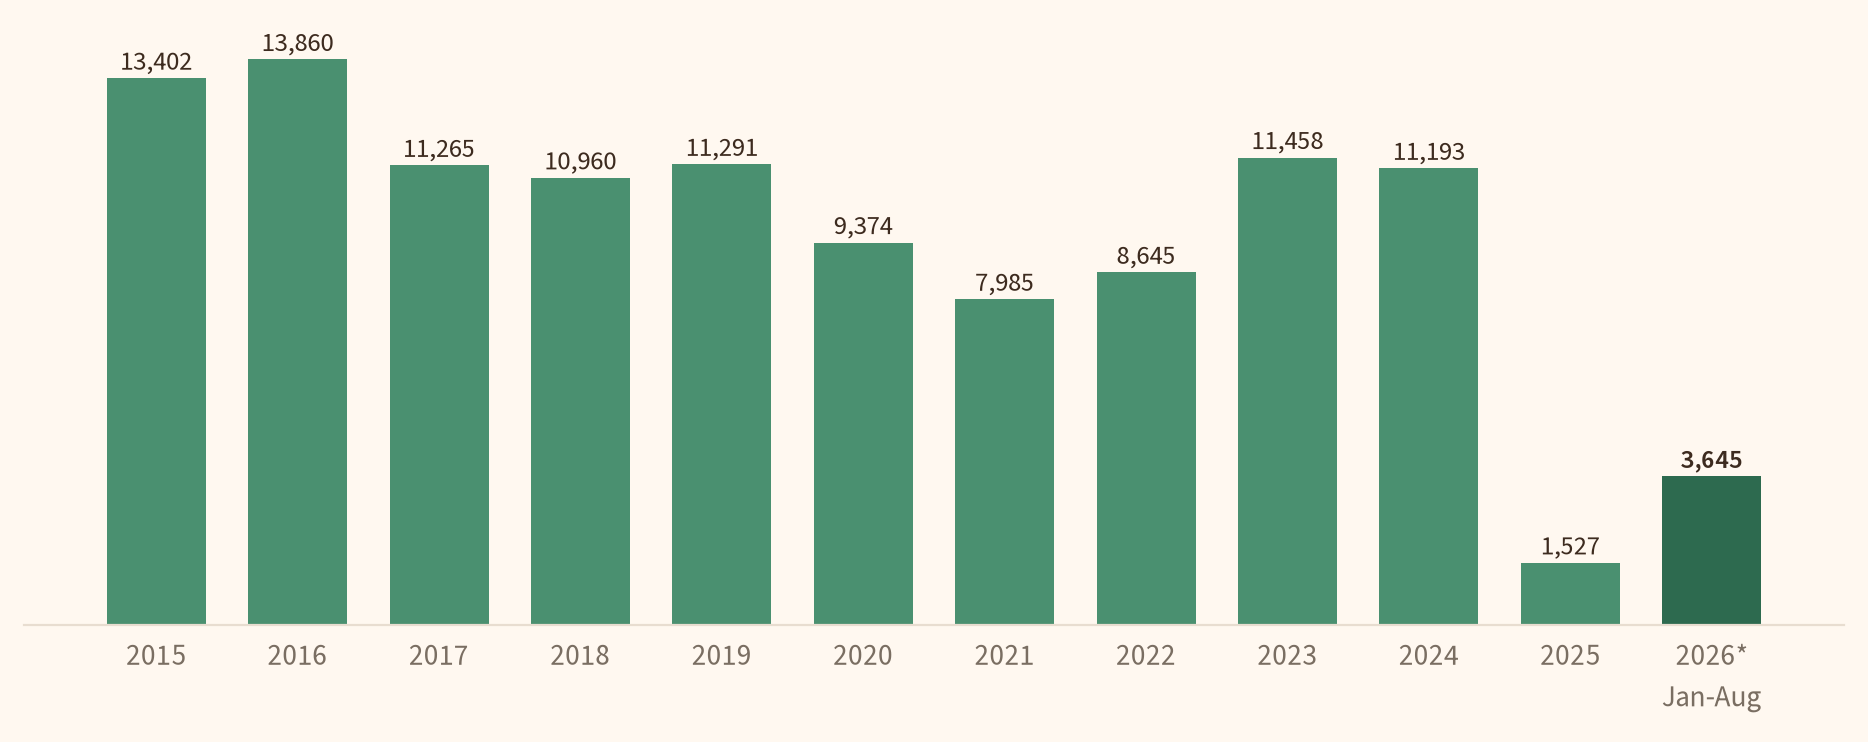

*Pathways: OPM's pathways_group field on the hire record. *2026 is January through August; every year here covers the same months. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026. All appointment types.*

**Pathways hires, January-August each year**

,"Pathways new hires, all appointment types"
year (January-August),
2015,13402
2016,13860
2017,11265
2018,10960
2019,11291
2020,9374
2021,7985
2022,8645
2023,11458


In [13]:
table("young_hires", "Permanent new hires under 30")
table("young_hires_by_occupation_2026", "The change in the young share, split into which jobs are being filled (mix) and age within the same jobs")
chart(8)
table("pathways_hires", "Pathways hires, January-August each year")

## Political appointments filled faster this term

#### Political appointees have refilled faster than in either of the last two terms
Political appointees, all appointment types: each January to November 2024, then monthly.

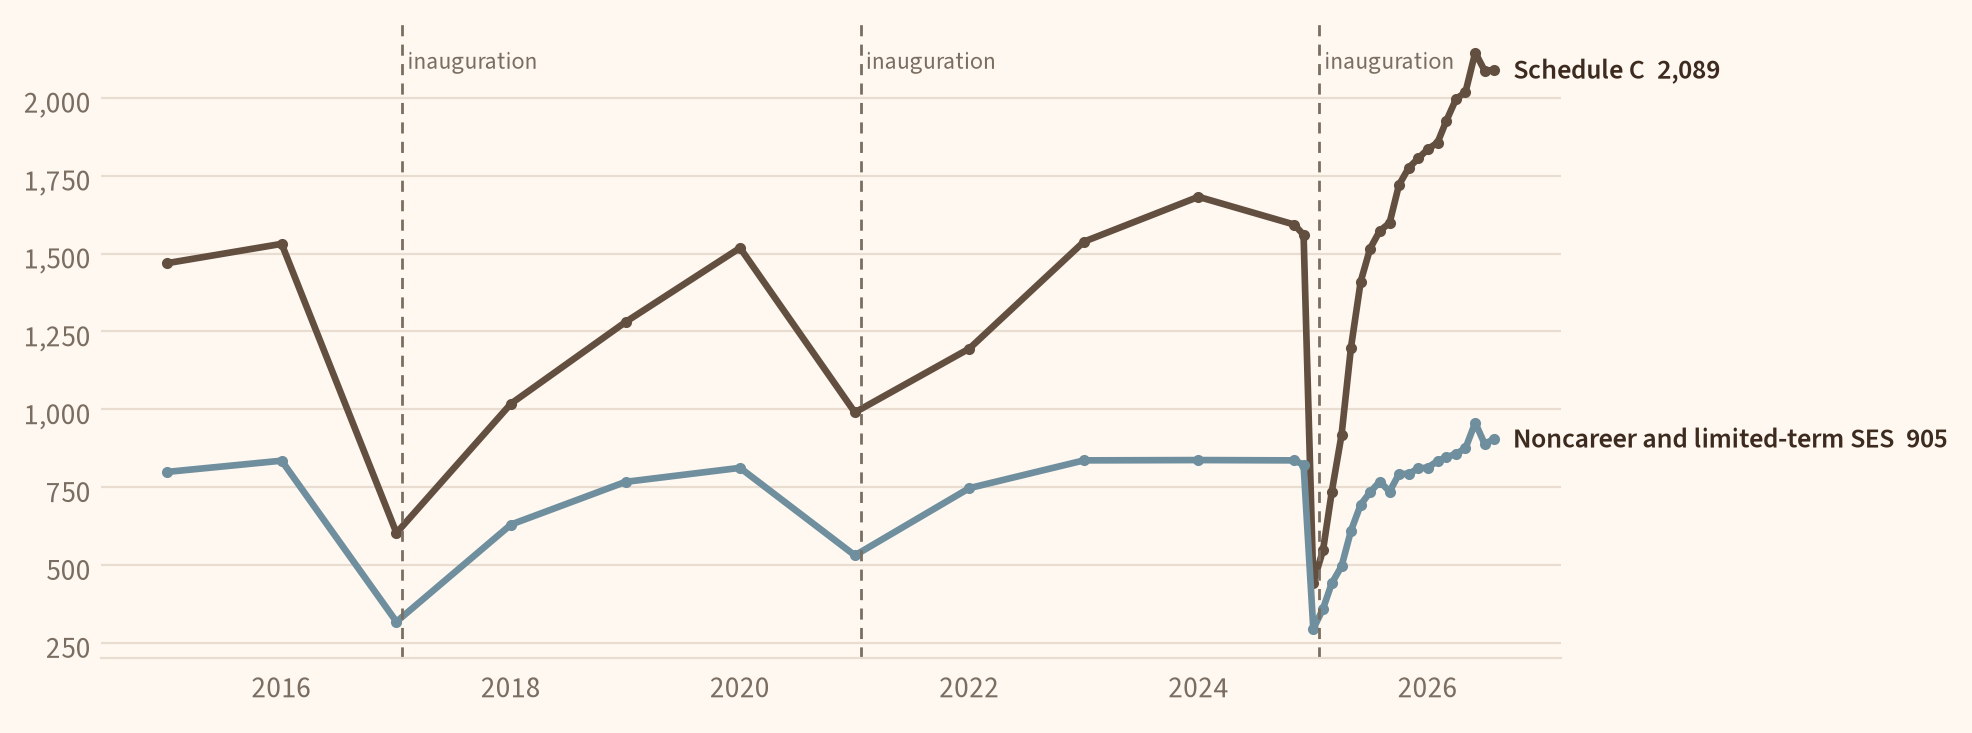

*Before November 2024 only January counts are read, so the lines skip the months between. Noncareer SES and limited-term SES are combined. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026. All appointment types.*

**Political and other at-will appointments, headcount (each January, then monthly)**

,Schedule C,noncareer SES,limited-term SES,Schedule Policy/Career,Schedule Policy/Career (nonpermanent),total
month,,,,,,
201501,1469,708,91,0,0,2268
201601,1531,749,86,0,0,2366
201701,603,215,103,0,0,921
201801,1018,545,85,0,0,1648
201901,1280,659,108,0,0,2047
202001,1518,705,107,0,0,2330
202101,990,410,121,0,0,1521
202201,1195,674,73,0,0,1942
202301,1538,753,83,0,0,2374


In [14]:
chart(9)
table("at_will_appointments", "Political and other at-will appointments, headcount (each January, then monthly)")

### Schedule Policy/Career

#### At the Office of Management and Budget, Schedule Policy/Career is most of the agency
Staff in Schedule Policy/Career, August 2026: the 10 agencies with the most.

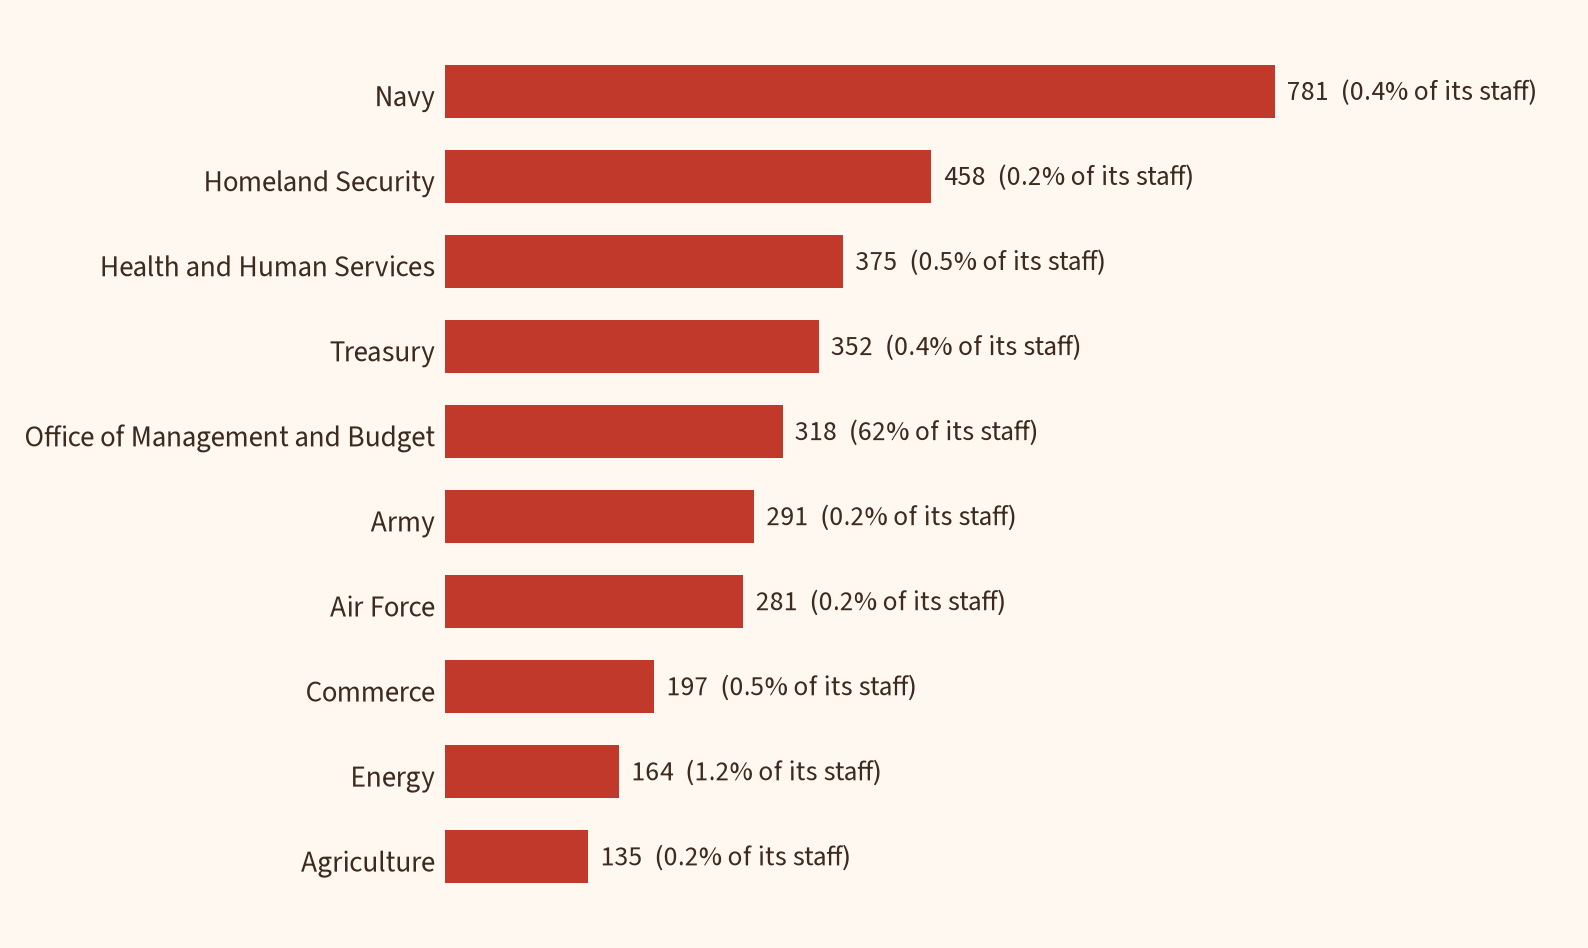

*It first appears in the June 2026 files. 10 of the 4,541 were hired into it; the files don't record moves between appointments, so the rest are counted as moved. Share of staff is of all the agency's staff, every appointment type. 4,476 hold it as a permanent appointment, so they are in every permanent figure in the post; 65 hold it as a nonpermanent one. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026. All appointment types.*

**Schedule Policy/Career as a share of each agency's staff (every agency with anyone in it)**

,name,"staff, August 2026",in Schedule Policy/Career,share of staff
agency,,,,
BO,Office Of Management And Budget,513,318,0.620
DQ,Denali Commission,12,2,0.167
AN,African Development Foundation,21,2,0.095
AU,Federal Labor Relations Authority,84,8,0.095
VD,Privacy And Civil Liberties Oversight,24,2,0.083
EB,Export-Import Bank Of The United States,340,27,0.079
QQ,Office Of National Drug Control Policy,63,5,0.079
BD,Merit Systems Protection Board,156,11,0.071
BT,Architectl & Trans Barrier Compliance Bd,32,2,0.062


**Schedule Policy/Career: largest occupations, and hires into it**

,in Schedule Policy/Career,name
0301,1132.0,Miscellaneous Administration And Program
0905,489.0,General Attorney
0343,467.0,Management And Program Analysis
0340,449.0,Program Management
0601,162.0,General Health Science
hires,10.0,"(hires into it, any file)"


In [15]:
chart(10)
table("schedule_policy_career_share_by_agency", "Schedule Policy/Career as a share of each agency's staff (every agency with anyone in it)")
table("schedule_policy_career_by_occupation", "Schedule Policy/Career: largest occupations, and hires into it")

## Do we see the ICE story elsewhere?

#### ICE's new officers are leaving far faster than Border Patrol's
People hired since September 2025 with no prior federal civilian or military service: running total each month, by whether they are still there.

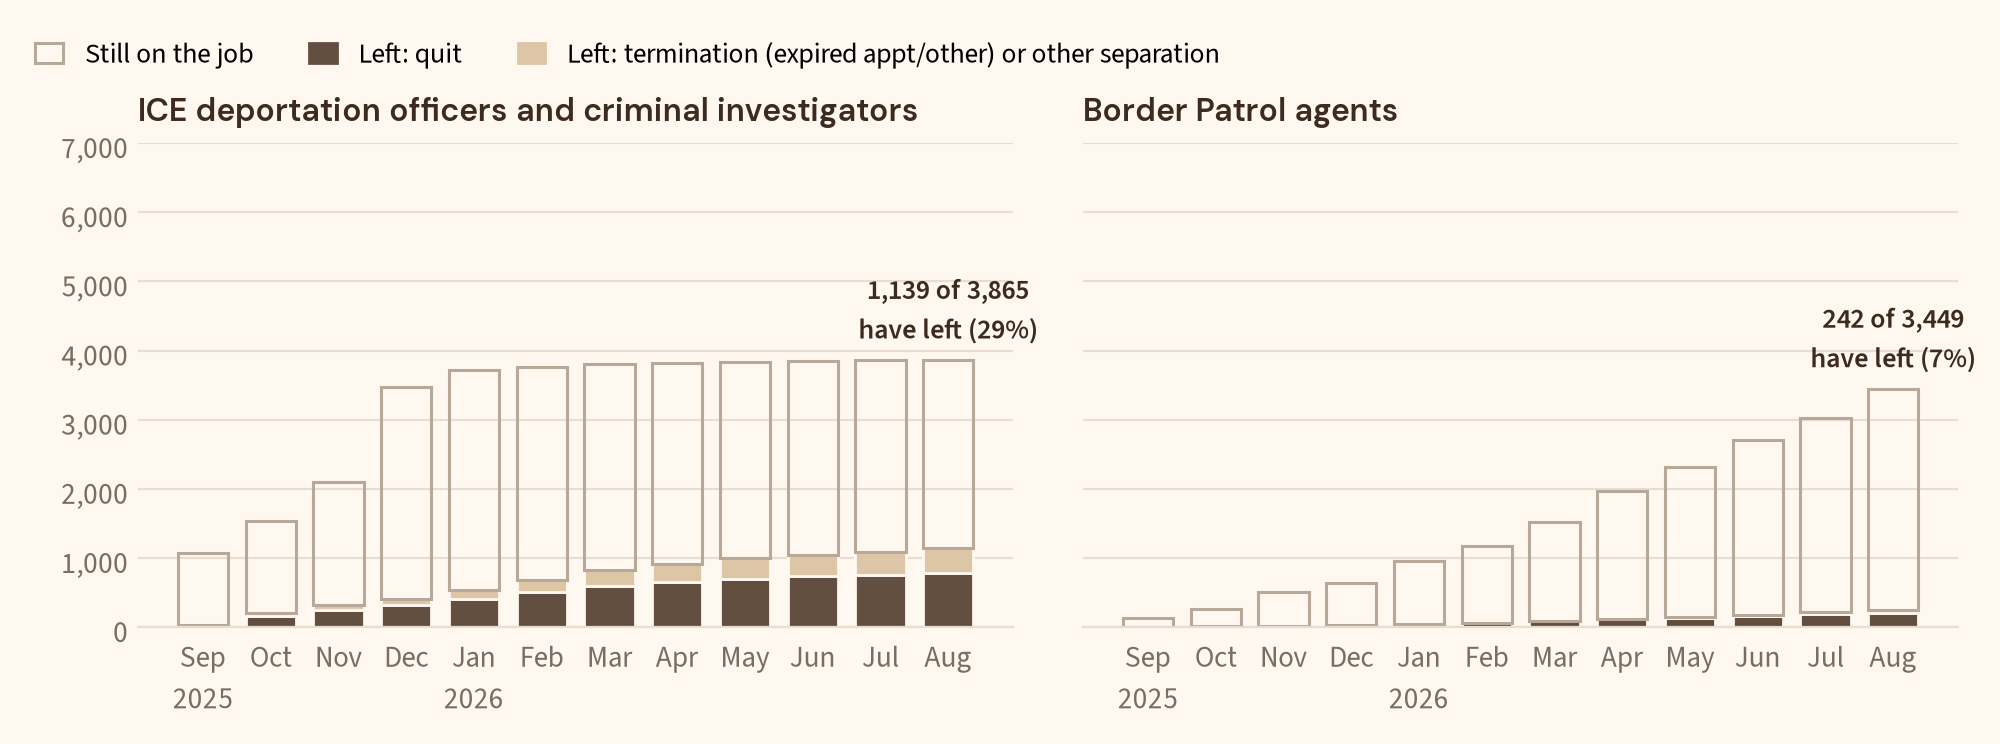

*New to federal service: under 3 months of creditable federal civilian or military service at hire. ICE officers: series 1801 and 1811; Border Patrol agents: series 1896; both on the GL law-enforcement pay plan. OPM's public files don't follow individual people, so a departure's hire month is its effective month minus its years of service; in every month the running count who have left is at most the running count hired (checked). Transfers to other agencies are not counted. Recent months fill in as late records arrive. OPM's "other separation" category includes removals for discipline or performance, and deaths. Source: OPM Enterprise Human Resources Integration (EHRI) data, files through August 2026 (entry law-enforcement pay plan). Permanent appointments.*

**The numbers in the chart**

,Deferred resignation (DRP),Layoff (RIF),Retirement,Quit,Other,group,hired_so_far
event_ym,,,,,,,
202509,0.0,0.0,0.0,28.0,3.0,ICE deportation officers and criminal investig...,1076.0
202510,0.0,0.0,0.0,166.0,44.0,ICE deportation officers and criminal investig...,1539.0
202511,0.0,0.0,0.0,255.0,68.0,ICE deportation officers and criminal investig...,2096.0
202512,0.0,0.0,0.0,323.0,91.0,ICE deportation officers and criminal investig...,3478.0
202601,0.0,0.0,0.0,403.0,132.0,ICE deportation officers and criminal investig...,3718.0
202602,0.0,0.0,0.0,509.0,171.0,ICE deportation officers and criminal investig...,3767.0
202603,0.0,0.0,0.0,596.0,229.0,ICE deportation officers and criminal investig...,3800.0
202604,0.0,0.0,0.0,658.0,260.0,ICE deportation officers and criminal investig...,3828.0
202605,0.0,0.0,0.0,704.0,292.0,ICE deportation officers and criminal investig...,3841.0


**New officers since September 2025: who has left, and how**

,hired,left,share left,quits,terminations,median months to quit,median months to termination
cohort,,,,,,,
ICE deportation officers and criminal investigators,3865,1139,0.295,777,358,1.8,3.0
Border Patrol agents,3449,242,0.070,212,1,1.0,0.9


...

,value
components that passed the size bar,22.000
"their new hires, September-December 2025",17991.000
"all new hires with no prior federal service, September-December 2025",19713.000
share,0.913


**Every agency component with 100+ hires new to federal service in each of the last three falls: share of each fall's class that left by the next August**

,component,hires_2023,hires_2024,hires_2025,left_2023,left_2024,left_2025,pct_left_2023,pct_left_2024,pct_left_2025,rise
u,,,,,,,,,,,
HSBB,IMMIGRATION AND CUSTOMS ENFORCEMENT,173.0,230.0,4206.0,8.0,25.0,1193.0,4.6,10.9,28.4,17.5
TR93,INTERNAL REVENUE SERVICE,3706.0,5702.0,1038.0,665.0,1272.0,372.0,17.9,22.3,35.8,13.5
HSBC,TRANSPORTATION SECURITY ADMINISTRATION,1076.0,2842.0,376.0,247.0,780.0,139.0,23.0,27.4,37.0,9.5
DJ03,BUREAU OF PRISONS/FEDERAL PRISON SYSTEM,692.0,1109.0,322.0,84.0,193.0,77.0,12.1,17.4,23.9,6.5
DD16,DEPARTMENT OF DEFENSE EDUCATION ACTIVITY,191.0,166.0,123.0,20.0,24.0,24.0,10.5,14.5,19.5,5.1
NV27,U.S. MARINE CORPS,273.0,309.0,106.0,15.0,23.0,12.0,5.5,7.4,11.3,3.9
IN10,NATIONAL PARK SERVICE,193.0,188.0,111.0,25.0,29.0,21.0,13.0,15.4,18.9,3.5
DD35,DEFENSE FINANCE AND ACCOUNTING SERVICE,203.0,291.0,153.0,38.0,56.0,32.0,18.7,19.2,20.9,1.7
DD07,DEFENSE LOGISTICS AGENCY,398.0,419.0,372.0,44.0,43.0,46.0,11.1,10.3,12.4,1.3


**Components where the share leaving rose 5+ points: who they hired and how those who left went**

,top series of 2025 hires,"how they left (OPM codes: SC quit, SJ termination, SL other)"
component,,
IMMIGRATION AND CUSTOMS ENFORCEMENT,"1801 General Inspection, Investigation, Enforc...",SC 817; SJ 372; SL 4
INTERNAL REVENUE SERVICE,"0962 Contact Representative (1,037); 2210 Info...",SC 320; SJ 46; SL 6
TRANSPORTATION SECURITY ADMINISTRATION,1802 Compliance Inspection And Support (373); ...,SC 109; SL 30
BUREAU OF PRISONS/FEDERAL PRISON SYSTEM,0007 Correctional Officer (219); 0610 Nurse (1...,SC 52; SL 13; SJ 11; SH 1
DEPARTMENT OF DEFENSE EDUCATION ACTIVITY,1702 Education And Training Technician (47); 1...,SC 22; SL 2


In [16]:
chart(1)
table("ice_vs_border_patrol", "New officers since September 2025: who has left, and how")
table("rookie_screen_coverage", "The fall-class comparison: which parts of government it covers")
table(None, "Every agency component with 100+ hires new to federal service in each of the last three falls: share of each fall's class that left by the next August", path="charts/rookie_screen.csv")
table("rookie_screen_behind", "Components where the share leaving rose 5+ points: who they hired and how those who left went")

## Checks

In [17]:
table("years_of_service_check", "OPM's years-of-service field against the leave service date, by file (OPM began counting from the leave service date in early 2026; every figure here uses the leave service date)")
table("years_of_service_as_published", "What reading OPM's years-of-service field as published would show, against the recomputed figures the post uses (same records)")
table("chart_claims", "Chart headlines and notes, checked against the data")
display(Markdown(open("checks/spot_check.md").read()))

**OPM's years-of-service field against the leave service date, by file (OPM began counting from the leave service date in early 2026; every figure here uses the leave service date)**

,file (share where OPM's years of service match the leave service date within 0.2 years),non-veterans,veterans
file type,,,
accessions,January 2015,0.933,0.382
accessions,January 2016,0.936,0.370
accessions,January 2017,0.906,0.402
accessions,January 2018,0.933,0.322
accessions,January 2019,0.933,0.302
accessions,January 2020,0.925,0.319
accessions,January 2021,0.920,0.330
accessions,January 2022,0.932,0.345
accessions,January 2023,0.919,0.323


**What reading OPM's years-of-service field as published would show, against the recomputed figures the post uses (same records)**

,"20+ years quits per 1,000 per month, as published","20+ years quits per 1,000 per month, recomputed","non-veteran new hires with prior service, as published","non-veteran new hires with prior service, recomputed"
year (January-August),,,,
2015,0.27,0.34,0.114,0.171
2016,0.24,0.35,0.113,0.169
2017,0.23,0.36,0.113,0.181
2018,0.26,0.42,0.109,0.168
2019,0.30,0.48,0.110,0.173
2020,0.27,0.40,0.119,0.192
2021,0.33,0.47,0.119,0.184
2022,0.45,0.65,0.130,0.193
2023,0.35,0.50,0.124,0.190


**Chart headlines and notes, checked against the data**

,claim,holds,wording used
chart,,,
ICE heading,Three in ten of ICE's new officers have alread...,True,Three in ten of ICE's new officers have alread...
Chart 1 title,ICE's new officers are leaving far faster than...,True,ICE's new officers are leaving far faster than...
2025 text,More than twice as many permanent employees le...,True,More than twice as many permanent employees le...
Chart 6 title,Attorneys are quitting at nearly twice their o...,True,Attorneys are quitting at nearly twice their o...
Chart 4 title,Long-serving staff are quitting at about their...,True,Long-serving staff are quitting at about their...
Chart 8 title,Pathways hiring is down about two-thirds,True,Pathways hiring is down about two-thirds
Chart 9 title,Political appointees have refilled faster than...,True,Political appointees have refilled faster than...
Chart 10 title,"At the Office of Management and Budget, Schedu...",True,"At the Office of Management and Budget, Schedu..."


# Spot check: headline numbers recomputed from OPM's raw files

`spot_check.py` downloads OPM's current files from data.opm.gov and recomputes these with pandas, sharing no code with extract.py or build.py. Files through 202608.

| Number | Recomputed | facts.md | Match |
|---|---|---|---|
| Departures effective in 2025, length of service reported (chart 3) | 317,527 | 317,527 | yes |
| Departures effective in 2025, all | 317,527 | 317,527 | yes |
| IRS tax examiners who left, January 2025 on | 5,218 | 5,218 | yes |
| IRS tax examiners who left in 2025 (chart 2) | 4,689 | 4,689 | yes |
| ... of them through DRP | 3,185 | 3,185 | yes |
| Attorney quits, January-August 2026 | 1,533 | 1,533 | yes |
| Quits by staff with 20+ years, 2026* | 2,446 | 2,446 | yes |
| ICE new officers hired since September 2025 | 3,865 | 3,865 | yes |
| ... of them who had left | 1,139 | 1,139 | yes |
| Permanent staff, January 2025 | 2,164,400 | 2,164,400 | yes |
| Permanent staff, August 2026 | 1,910,145 | 1,910,145 | yes |
| January 2025 staff with a length of service (chart 4's denominators) | 2,164,394 | 2,164,394 | yes |
| Retirement-eligible staff (at least), January 2026 | 165,412 | 165,412 | yes |
| Non-veteran new hires with prior service, 2026* | 13,949 | 13,949 | yes |
| Share of permanent new hires under 30, 2026* | 31.7% | 31.7% | yes |
| Share of permanent new hires with a bachelor's or more, all agencies, 2026* | 44.7% | 44.7% | yes |

January 2025 staff with no length of service reported: 6.
